# Customer Churn Analysis and Prediction
## An AI-Powered Customer Retention Dashboard

---

**Author:** Umar Rahi  
**Internship:** AICTE | IBM SkillsBuild Data Analytics with AI Internship 2026  
**Organization:** BharatCares  
**Date:** 2026  

---

## Project Introduction

Customer churn — the loss of existing customers to competitors or voluntary cancellations — is a critical business problem across subscription-based industries. Acquiring new customers typically costs 5–7× more than retaining existing ones, making churn prediction and prevention a high-ROI investment.

This notebook performs a complete, end-to-end analysis of a customer dataset from a subscription service. We:

1. Inspect, clean, and integrate three related data tables
2. Define a churn target rigorously, avoiding data leakage
3. Perform exploratory data analysis (EDA) with visualization
4. Build an exploratory ML workflow (clearly noting sample-size limitations)
5. Derive actionable business recommendations

### Dataset Overview
| Sheet | Rows | Description |
|---|---|---|
| db_customer | 22 (21 valid) | Customer demographics |
| db_subscription | 21 | Subscription details, charges, churn info |
| db_support | 9 | Support tickets (7 unique customers) |

**⚠️ Transparency Notice:** This dataset contains 21 customers. All findings are descriptive statistics of this specific cohort and should not be generalized to a larger population without additional data.

## 1. Imports and Configuration

In [1]:
# Standard library
import os
import sys
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')

# Third-party
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# Scikit-learn
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, RocCurveDisplay
)

# Local src modules
PROJECT_ROOT = Path('.').resolve()
sys.path.insert(0, str(PROJECT_ROOT))

from src.data_processing import load_and_prepare, DEFAULT_DATA_PATH, REFERENCE_DATE
from src.analysis import (
    compute_kpis, churn_by_column, cancellation_reasons,
    monthly_charges_summary, cltv_summary, support_churn_summary
)
from src.model import load_model_results, LEAKAGE_COLS

# Visualization settings
sns.set_theme(style='whitegrid', palette='Blues_r')
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
})

PALETTE = {'Retained': '#2563eb', 'Churned': '#dc2626'}
FIGURES_DIR = PROJECT_ROOT / 'outputs' / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 30)
pd.set_option('display.float_format', '{:.2f}'.format)

print(f'Project root: {PROJECT_ROOT}')
print(f'Reference date: {REFERENCE_DATE.date()}')
print(f'Figures output: {FIGURES_DIR}')

Project root: C:\Users\urahi\Desktop\churn analysis\Customer-Churn-Analysis
Reference date: 2025-01-01
Figures output: C:\Users\urahi\Desktop\churn analysis\Customer-Churn-Analysis\outputs\figures


## 2. Dataset Loading

The workbook `customer_churn_data_raw.xlsx` must be placed in the `data/` folder relative to this notebook. See `data/README.md` for instructions.

In [2]:
# Load raw sheets directly for initial inspection
import openpyxl

wb_path = PROJECT_ROOT / 'data' / 'customer_churn_data_raw.xlsx'
print(f'Loading from: {wb_path}')
print(f'File exists: {wb_path.exists()}')

raw_sheets = pd.read_excel(wb_path, sheet_name=None, engine='openpyxl')

print(f'\nWorksheets found: {list(raw_sheets.keys())}')
for name, df_raw in raw_sheets.items():
    print(f'  {name}: {df_raw.shape[0]} rows × {df_raw.shape[1]} cols')

Loading from: C:\Users\urahi\Desktop\churn analysis\Customer-Churn-Analysis\data\customer_churn_data_raw.xlsx
File exists: True

Worksheets found: ['db_customer', 'db_subscription', 'db_support']
  db_customer: 21 rows × 8 cols
  db_subscription: 21 rows × 11 cols
  db_support: 9 rows × 6 cols


## 3. Initial Data Inspection

In [3]:
# === db_customer ===
df_cust_raw = raw_sheets['db_customer']
print('=== db_customer ===' )
print(df_cust_raw.dtypes)
df_cust_raw.head(22)

=== db_customer ===
customerid               str
name                     str
country                  str
state                    str
gender                   str
dob           datetime64[us]
interests                str
pincode              float64
dtype: object


,customerid,name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12,travel,NaN
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23,NaN,NaN
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15,movie,NaN
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30,NaN,NaN
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05,drama,NaN
5,0013-MHZWF,durga,NaN,Delhi,Women,1988-12-10,NaN,NaN
6,0013-SMEOE,mina,India,Meghalaya,Female,1976-09-21,NaN,NaN
7,0014-BMAQU,madan,India,Rajasthan,Male,1999-03-14,NaN,NaN
8,0015-UOCOJ,maya,NaN,Kathmandu,Women,1985-07-07,NaN,NaN
9,0016-QLJIS,arjun,Nepal,Kathmandu,Male,1993-10-29,NaN,NaN


In [4]:
# === db_subscription ===
df_sub_raw = raw_sheets['db_subscription']
print('=== db_subscription ===')
print(df_sub_raw.dtypes)
df_sub_raw

=== db_subscription ===
customerid                     str
subscription_start_date        str
subscription_type              str
renewal_date                   str
plan_type                      str
contract_type                  str
cancellation_date              str
cancellation_reason            str
monthly_charges            float64
cltv                         int64
churn_score                  int64
dtype: object


,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaN,NaN,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaN,NaN,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaN,NaN,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88
5,0013-MHZWF,2022-06-18,Paid,2025-06-18,Standard,Annual,NaN,NaN,17.99,720,22
6,0013-SMEOE,2021-09-30,Refferal,2024-09-30,Basic,Monthly,2024-11-15,Not enough content,8.99,230,79
7,0014-BMAQU,2020-02-14,Organic,2025-02-14,Premium,Annual,NaN,NaN,22.99,1840,5
8,0015-UOCOJ,2023-07-22,Organic,2024-07-22,Standard,Monthly,NaN,NaN,13.99,240,34
9,0016-QLJIS,2022-04-03,Organic,2025-04-03,Basic,Annual,NaN,NaN,6.99,335,41


In [5]:
# === db_support ===
df_sup_raw = raw_sheets['db_support']
print('=== db_support ===')
print(df_sup_raw.dtypes)
df_sup_raw

=== db_support ===
customerid                   str
complaint_date    datetime64[us]
escalations                  str
csat_score                 int64
col_1                    float64
comment                      str
dtype: object


,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0003-MKNFE,2024-08-28,N,60,NaN,service issue
1,0003-MKNFE,2024-08-28,Y,10,NaN,demaned refund
2,0013-EXCHZ,2024-01-20,Y,20,NaN,NaN
3,0013-MHZWF,2025-03-18,N,90,NaN,guidance to renew
4,0013-SMEOE,2024-11-01,N,30,NaN,NaN
5,0017-IUDMW,2024-04-10,Y,25,NaN,NaN
6,0019-EFAEP,2024-09-27,Y,30,NaN,NaN
7,0022-TCJCI,2024-09-13,Y,10,NaN,NaN
8,0022-TCJCI,2024-09-14,N,90,NaN,received refund


In [6]:
# Missing values per sheet
print('--- Missing values ---')
for name, df_raw in raw_sheets.items():
    print(f'\n{name}:')
    mv = df_raw.isnull().sum()
    print(mv[mv > 0] if mv.any() else '  (none)')

# Duplicates
print('\n--- Duplicate rows ---')
for name, df_raw in raw_sheets.items():
    print(f'  {name}: {df_raw.duplicated().sum()} duplicates')

--- Missing values ---

db_customer:
country       3
interests    17
pincode      21
dtype: int64

db_subscription:
cancellation_date      15
cancellation_reason    15
dtype: int64

db_support:
col_1      9
comment    5
dtype: int64

--- Duplicate rows ---
  db_customer: 0 duplicates
  db_subscription: 0 duplicates
  db_support: 0 duplicates


In [7]:
# Customer ID consistency across tables
cust_ids = set(df_cust_raw['customerid'].dropna())
sub_ids  = set(df_sub_raw['customerid'].dropna())
sup_ids  = set(df_sup_raw['customerid'].dropna())

print(f'Unique IDs in db_customer:    {len(cust_ids)}')
print(f'Unique IDs in db_subscription:{len(sub_ids)}')
print(f'Unique IDs in db_support:     {len(sup_ids)}')
print(f'\nIn subscription but NOT customer: {sub_ids - cust_ids}')
print(f'In customer but NOT subscription: {cust_ids - sub_ids}')
print(f'Support IDs not in subscription:  {sup_ids - sub_ids}')

Unique IDs in db_customer:    21
Unique IDs in db_subscription:21
Unique IDs in db_support:     7

In subscription but NOT customer: set()
In customer but NOT subscription: set()
Support IDs not in subscription:  set()


## 4. Data Cleaning and Validation

We use the reusable `src/data_processing.py` pipeline. Key transformations:

| Issue | Resolution |
|---|---|
| Blank row at end of db_customer | Dropped (no customerid) |
| Gender inconsistencies (Men/Women) | Mapped to Male/Female |
| Missing `country` for 3 customers | Inferred from state where possible |
| Typo: `Refferal` in subscription_type | Corrected to `Referral` |
| `col_1` empty column in db_support | Dropped |
| Multiple support tickets per customer | Aggregated to 1 row per customer |
| Date columns stored as strings | Converted to datetime |
| `churn_score` — unknown provenance | Excluded from predictive features |

In [8]:
# Run the full pipeline
data = load_and_prepare(wb_path)

df_master      = data['master']
df_customer    = data['customer']
df_subscription= data['subscription']
df_support_raw = data['support_raw']
df_support_agg = data['support_agg']

print('Pipeline complete.')
print(f'  Master (merged) rows: {len(df_master)}')
print(f'  Support tickets:      {len(df_support_raw)}')
print(f'  Unique customers with tickets: {df_support_raw["customerid"].nunique()}')

Pipeline complete.
  Master (merged) rows: 21
  Support tickets:      9
  Unique customers with tickets: 7


In [9]:
# Cleaned db_customer
print('Cleaned db_customer:')
df_customer[['customerid','country','state','gender','age','age_group','interests']].head(21)

Cleaned db_customer:


,customerid,country,state,gender,age,age_group,interests
0,0002-ORFBO,India,Maharashtra,Male,42.70,35–44,travel
1,0003-MKNFE,India,Karnataka,Male,29.10,25–34,NaN
2,0004-TLHLJ,India,Delhi,Female,46.90,45–54,movie
3,0011-IGKFF,India,Nagaland,Male,23.30,<25,NaN
4,0013-EXCHZ,India,Delhi,Female,34.70,25–34,drama
5,0013-MHZWF,India,Delhi,Female,36.10,35–44,NaN
6,0013-SMEOE,India,Meghalaya,Female,48.30,45–54,NaN
7,0014-BMAQU,India,Rajasthan,Male,25.80,25–34,NaN
8,0015-UOCOJ,NaN,Kathmandu,Female,39.50,35–44,NaN
9,0016-QLJIS,Nepal,Kathmandu,Male,31.20,25–34,NaN


In [10]:
# Cleaned db_subscription with churn target
print('Cleaned db_subscription:')
df_subscription[['customerid','subscription_type','plan_type','contract_type',
                 'monthly_charges','cltv','tenure_months','churned','cancellation_reason']]

Cleaned db_subscription:


,customerid,subscription_type,plan_type,contract_type,monthly_charges,cltv,tenure_months,churned,cancellation_reason
0,0002-ORFBO,Referral,Standard,Annual,13.99,627,45.60,0,NaN
1,0003-MKNFE,Paid,Premium,Annual,12.99,1150,53.00,1,Switched to competitor
2,0004-TLHLJ,Organic,Basic,Monthly,6.99,210,25.40,0,NaN
3,0011-IGKFF,Paid,Premium,Annual,22.99,1725,67.80,0,NaN
4,0013-EXCHZ,Referral,Standard,Monthly,13.99,195,23.90,1,Too expensive
5,0013-MHZWF,Paid,Standard,Annual,17.99,720,30.50,0,NaN
6,0013-SMEOE,Referral,Basic,Monthly,8.99,230,39.10,1,Not enough content
7,0014-BMAQU,Organic,Premium,Annual,22.99,1840,58.60,0,NaN
8,0015-UOCOJ,Organic,Standard,Monthly,13.99,240,17.40,0,NaN
9,0016-QLJIS,Organic,Basic,Annual,6.99,335,33.00,0,NaN


In [11]:
# Validate join
from src.data_processing import validate_join_coverage
join_report = validate_join_coverage(df_master, df_customer)
print('Join coverage report:')
for k, v in join_report.items():
    print(f'  {k}: {v}')

Join coverage report:
  subscription_rows: 21
  customer_rows: 21
  ids_in_sub_not_customer: set()
  ids_in_customer_not_sub: set()
  duplicate_rows_in_master: 0


## 5. Data Integration and Feature Engineering

### Churn Target Definition

**Definition:** A customer is classified as **churned** (`churned = 1`) if `cancellation_date` is not null.  
**Rationale:** Cancellation date is the objective fact of service termination. No subjective threshold is applied.

**Leakage prevention:** The following columns are **excluded** from predictive features:
- `cancellation_date` — post-cancellation fact (occurs at or after churn)
- `cancellation_reason` — only known after cancellation
- `churn_score` — origin unknown; may have been calculated using post-hoc information
- `renewal_date` — closely tied to subscription lifecycle events

### Derived Features
| Feature | Derivation | Justification |
|---|---|---|
| `tenure_months` | (REFERENCE_DATE - subscription_start_date) / 30.44 | Customer age in months; early churn proxy |
| `age` | (REFERENCE_DATE - dob) / 365.25 | Demographic signal |
| `age_group` | Binned from age | Reduces cardinality for modelling |
| `complaint_count` | Count of support tickets | Higher contact = friction signal |
| `has_escalation` | Any escalation in tickets | Strong satisfaction indicator |
| `avg_csat_score` | Mean CSAT across tickets | Overall support satisfaction |


In [12]:
# Final master dataframe
print(f'Master shape: {df_master.shape}')
print(f'Churn target distribution:')
print(df_master['churned'].value_counts().rename({0: 'Retained', 1: 'Churned'}).to_string())
print(f'Churn rate: {df_master["churned"].mean()*100:.1f}%')

Master shape: (21, 26)
Churn target distribution:
churned
Retained    15
Churned      6
Churn rate: 28.6%


In [13]:
# Master dataframe overview
df_master.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 26 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               21 non-null     str           
 1   subscription_start_date  21 non-null     datetime64[us]
 2   subscription_type        21 non-null     str           
 3   renewal_date             21 non-null     datetime64[us]
 4   plan_type                21 non-null     str           
 5   contract_type            21 non-null     str           
 6   cancellation_date        6 non-null      datetime64[us]
 7   cancellation_reason      6 non-null      str           
 8   monthly_charges          21 non-null     float64       
 9   cltv                     21 non-null     int64         
 10  churn_score              21 non-null     int64         
 11  churned                  21 non-null     int64         
 12  tenure_months            21 non-null     float64 

In [14]:
df_master.describe().round(2)

,subscription_start_date,renewal_date,cancellation_date,monthly_charges,cltv,churn_score,churned,tenure_months,dob,pincode,age,complaint_count,avg_csat_score,min_csat_score
count,21,21,6,21.00,21.00,21.00,21.00,21.00,21,0.00,21.00,21.00,7.00,7.00
mean,2021-11-20 18:17:08.571428,2025-02-15 17:08:34.285714,2024-08-06 16:00:00,18.85,823.52,43.29,0.29,37.37,1989-08-26 12:34:17.142857,NaN,35.34,0.43,40.00,30.71
min,2019-05-10 00:00:00,2024-01-05 00:00:00,2024-02-28 00:00:00,6.99,42.00,3.00,0.00,15.60,1976-09-21 00:00:00,NaN,20.10,0.00,20.00,10.00
25%,2020-10-09 00:00:00,2024-08-25 00:00:00,2024-06-03 00:00:00,12.99,240.00,14.00,0.00,24.00,1982-04-12 00:00:00,NaN,29.10,0.00,27.50,15.00
50%,2022-01-19 00:00:00,2025-04-03 00:00:00,2024-09-12 00:00:00,13.99,640.00,34.00,0.00,35.40,1990-05-05 00:00:00,NaN,34.70,0.00,30.00,25.00
75%,2022-12-31 00:00:00,2025-07-07 00:00:00,2024-10-19 06:00:00,20.99,1150.00,76.00,1.00,50.80,1995-11-23 00:00:00,NaN,42.70,1.00,42.50,30.00
max,2023-09-14 00:00:00,2025-12-31 00:00:00,2024-11-15 00:00:00,92.99,2185.00,99.00,1.00,67.80,2004-12-01 00:00:00,NaN,48.30,2.00,90.00,90.00
std,NaN,NaN,NaN,17.75,668.91,32.29,0.46,15.58,NaN,NaN,8.53,0.68,23.98,27.45


## 6. Exploratory Data Analysis

All statistics below are computed from the 21-customer dataset. Due to the small sample, percentages should be interpreted as descriptive of this cohort only.

In [15]:
# Top-level KPIs
kpis = compute_kpis(df_master)
print('=== KEY PERFORMANCE INDICATORS ===')
for k, v in kpis.items():
    print(f'  {k:<35} {v}')

=== KEY PERFORMANCE INDICATORS ===
  total_customers                     21
  churned_customers                   6
  retained_customers                  15
  churn_rate_pct                      28.6
  total_monthly_charges               321.85
  avg_monthly_charge                  18.85
  total_cltv                          17294
  churned_cltv                        2047
  avg_cltv                            824.0
  avg_cltv_churned                    341.0
  avg_cltv_retained                   1016.0
  complaint_rate_pct                  33.3
  escalation_rate_pct                 23.8


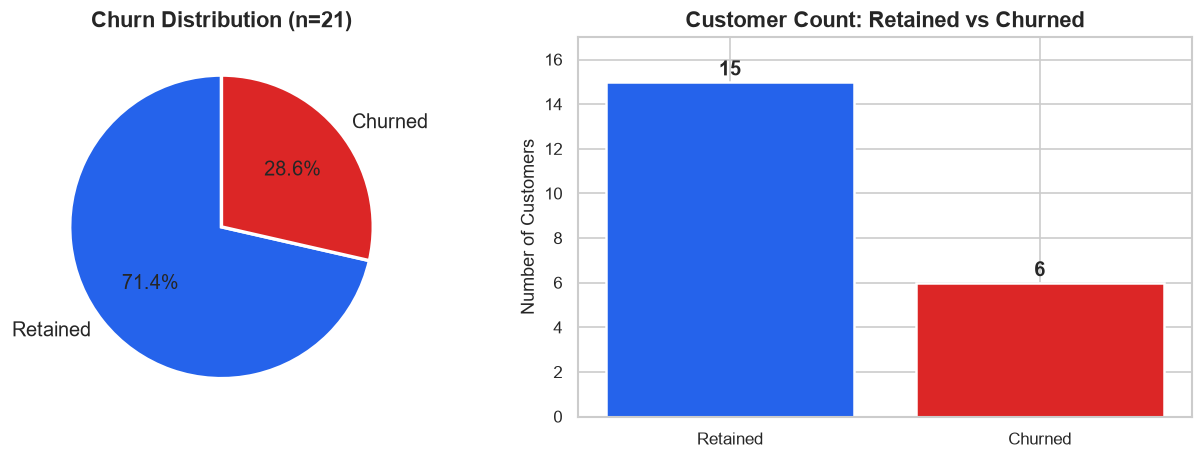

Churn rate: 28.6% (6 of 21 customers)


In [16]:
# --- Fig 1: Churn Distribution ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

churn_counts = df_master['churned'].map({1: 'Churned', 0: 'Retained'}).value_counts()

# Pie
axes[0].pie(
    churn_counts.values,
    labels=churn_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['#2563eb', '#dc2626'],
    textprops={'fontsize': 12},
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)
axes[0].set_title('Churn Distribution (n=21)', fontweight='bold')

# Bar
bars = axes[1].bar(
    churn_counts.index, churn_counts.values,
    color=['#2563eb', '#dc2626'], edgecolor='white', linewidth=1.5
)
for bar, count in zip(bars, churn_counts.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
                 str(count), ha='center', va='bottom', fontweight='bold')
axes[1].set_title('Customer Count: Retained vs Churned', fontweight='bold')
axes[1].set_ylabel('Number of Customers')
axes[1].set_ylim(0, max(churn_counts.values) + 2)

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig01_churn_distribution.png', bbox_inches='tight')
plt.show()
print(f'Churn rate: {kpis["churn_rate_pct"]}% ({kpis["churned_customers"]} of {kpis["total_customers"]} customers)')

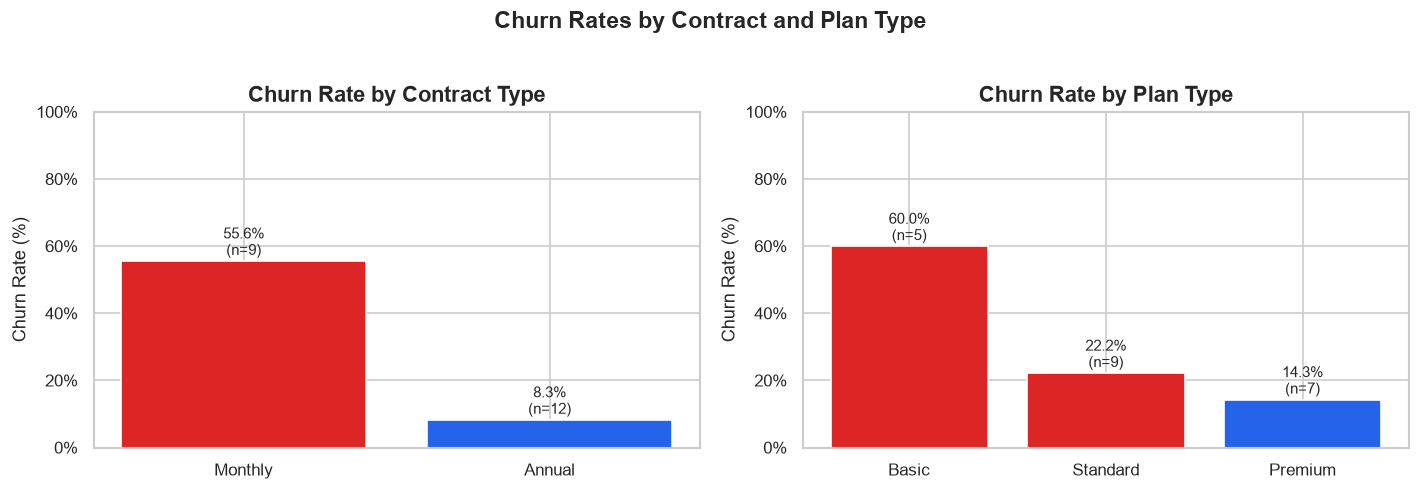

Contract type breakdown:
contract_type  total  churned  retained  churn_rate_pct
      Monthly      9        5         4           55.60
       Annual     12        1        11            8.30

Plan type breakdown:
plan_type  total  churned  retained  churn_rate_pct
    Basic      5        3         2           60.00
 Standard      9        2         7           22.20
  Premium      7        1         6           14.30


In [17]:
# --- Fig 2: Churn by Contract Type and Plan Type ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

cb_contract = churn_by_column(df_master, 'contract_type')
cb_plan     = churn_by_column(df_master, 'plan_type')

for ax, cb, col_name, title in [
    (axes[0], cb_contract, 'contract_type', 'Churn Rate by Contract Type'),
    (axes[1], cb_plan,     'plan_type',     'Churn Rate by Plan Type'),
]:
    colors = ['#dc2626' if r > 20 else '#2563eb' for r in cb['churn_rate_pct']]
    bars = ax.bar(cb[col_name], cb['churn_rate_pct'], color=colors, edgecolor='white')
    for bar, (_, row) in zip(bars, cb.iterrows()):
        ax.text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.5,
            f"{row['churn_rate_pct']}%\n(n={row['total']})",
            ha='center', va='bottom', fontsize=9
        )
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel('Churn Rate (%)')
    ax.set_ylim(0, 100)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())

plt.suptitle('Churn Rates by Contract and Plan Type', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig02_churn_by_segment.png', bbox_inches='tight')
plt.show()

print('Contract type breakdown:')
print(cb_contract.to_string(index=False))
print('\nPlan type breakdown:')
print(cb_plan.to_string(index=False))

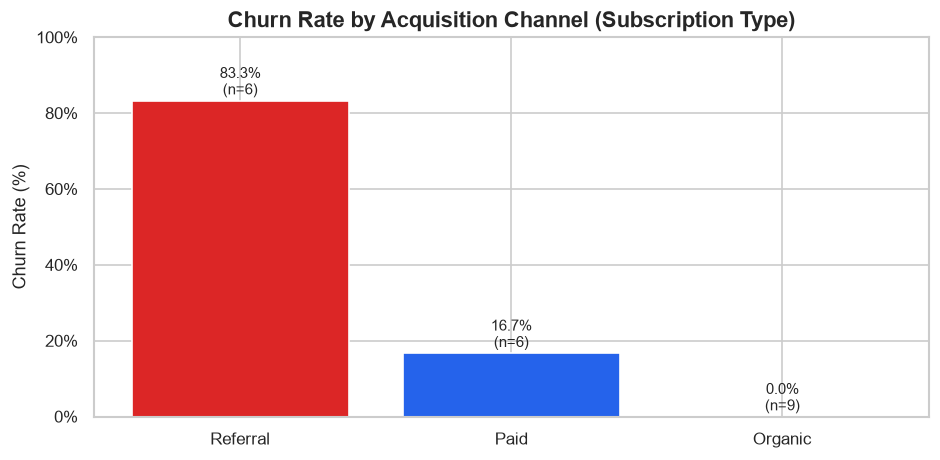

subscription_type  total  churned  retained  churn_rate_pct
         Referral      6        5         1           83.30
             Paid      6        1         5           16.70
          Organic      9        0         9            0.00


In [18]:
# --- Fig 3: Churn by Subscription Type ---
cb_sub = churn_by_column(df_master, 'subscription_type')

fig, ax = plt.subplots(figsize=(8, 4))
colors = ['#dc2626' if r > 20 else '#2563eb' for r in cb_sub['churn_rate_pct']]
bars = ax.bar(cb_sub['subscription_type'], cb_sub['churn_rate_pct'], color=colors, edgecolor='white')
for bar, (_, row) in zip(bars, cb_sub.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.5,
        f"{row['churn_rate_pct']}%\n(n={row['total']})",
        ha='center', va='bottom', fontsize=9
    )
ax.set_title('Churn Rate by Acquisition Channel (Subscription Type)', fontweight='bold')
ax.set_ylabel('Churn Rate (%)')
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig03_churn_by_subscription_type.png', bbox_inches='tight')
plt.show()
print(cb_sub.to_string(index=False))

Cancellation reasons:
                reason  count   pct
Switched to competitor      2 33.30
         Too expensive      1 16.70
    Not enough content      1 16.70
Poor streaming quality      1 16.70
Forgot to cancel trial      1 16.70


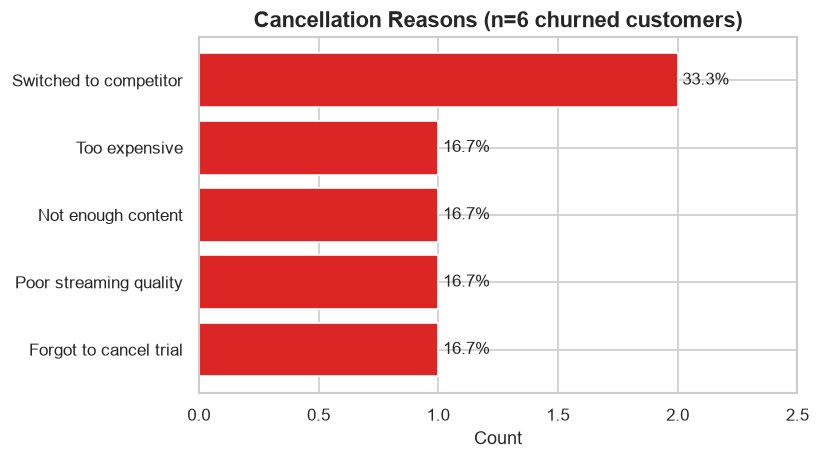

In [19]:
# --- Fig 4: Cancellation Reasons ---
reasons = cancellation_reasons(df_master)
print('Cancellation reasons:')
print(reasons.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(reasons['reason'], reasons['count'], color='#dc2626', edgecolor='white')
for i, (_, row) in enumerate(reasons.iterrows()):
    ax.text(row['count'] + 0.02, i, f"{row['pct']}%", va='center', fontsize=10)
ax.set_title(f'Cancellation Reasons (n={len(df_master[df_master["churned"]==1])} churned customers)', fontweight='bold')
ax.set_xlabel('Count')
ax.set_xlim(0, reasons['count'].max() + 0.5)
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig04_cancellation_reasons.png', bbox_inches='tight')
plt.show()

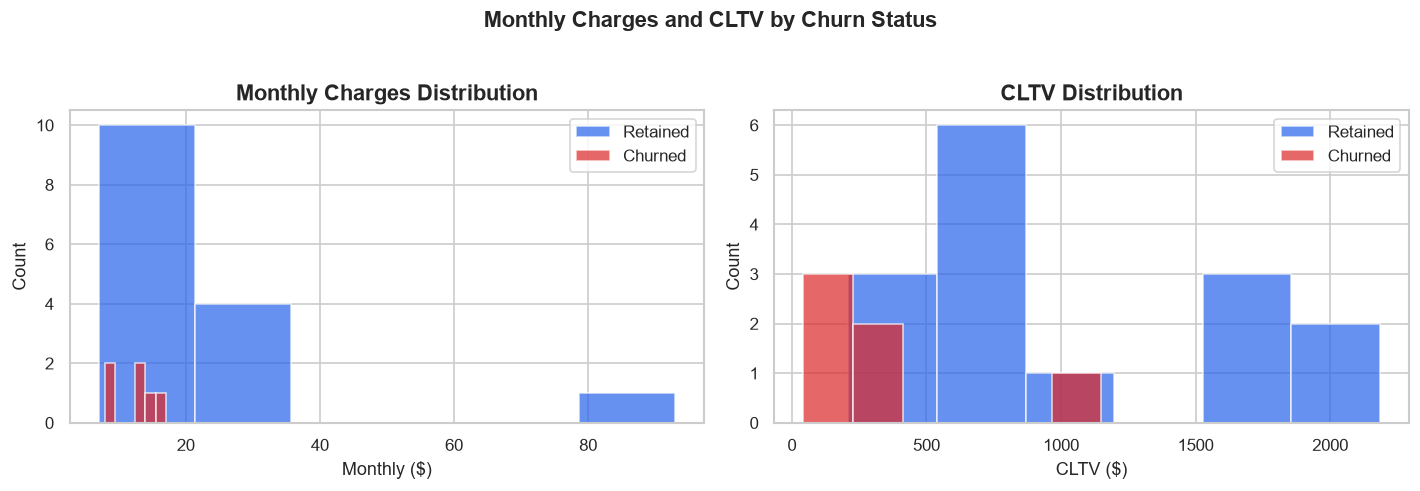

Monthly charges summary by churn status:
 churned  count  mean   std  min   25%   50%   75%   max
Retained  15.00 21.46 20.51 6.99 13.99 13.99 22.99 92.99
 Churned   6.00 12.32  3.33 7.99  9.99 12.99 13.74 16.99

CLTV summary by churn status:
 churned  count    mean    std    min    25%    50%     75%     max
Retained  15.00 1016.00 664.00 210.00 588.00 790.00 1668.00 2185.00
 Churned   6.00  341.00 404.00  42.00 169.00 212.00  260.00 1150.00


In [20]:
# --- Fig 5: Monthly Charges and CLTV Distributions ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

status_map = df_master['churned'].map({1: 'Churned', 0: 'Retained'})

for ax, col, title, unit in [
    (axes[0], 'monthly_charges', 'Monthly Charges Distribution', '$'),
    (axes[1], 'cltv',            'CLTV Distribution',            '$'),
]:
    for status, color in PALETTE.items():
        subset = df_master.loc[status_map == status, col].dropna()
        ax.hist(subset, alpha=0.7, color=color, label=status, bins=6, edgecolor='white')
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel(f'{title.split()[0]} ({unit})')
    ax.set_ylabel('Count')
    ax.legend()

plt.suptitle('Monthly Charges and CLTV by Churn Status', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig05_charges_cltv_dist.png', bbox_inches='tight')
plt.show()

print('Monthly charges summary by churn status:')
print(monthly_charges_summary(df_master).to_string(index=False))
print('\nCLTV summary by churn status:')
print(cltv_summary(df_master).to_string(index=False))

Support vs Churn summary:
 churned  avg_complaints pct_with_escalation  avg_csat
Retained            0.07            Retained     90.00
 Churned            1.33                0.83     31.67


TypeError: Axes.boxplot() got an unexpected keyword argument 'labels'. Did you mean 'label'?

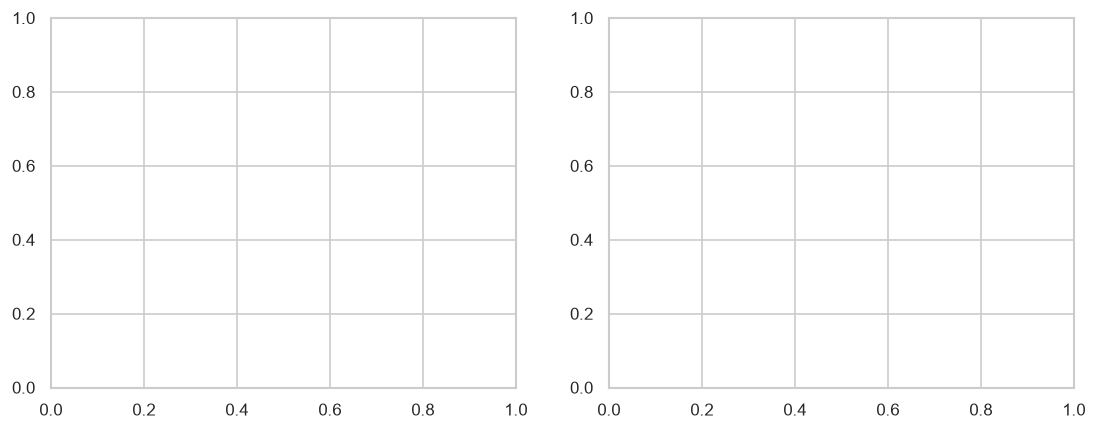

In [21]:
# --- Fig 6: Support and Escalation Analysis ---
supp_summary = support_churn_summary(df_master)
print('Support vs Churn summary:')
print(supp_summary.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Complaint count boxplot
data_for_plot = [
    df_master.loc[df_master['churned'] == 0, 'complaint_count'].values,
    df_master.loc[df_master['churned'] == 1, 'complaint_count'].values,
]
bp = axes[0].boxplot(data_for_plot, labels=['Retained', 'Churned'], patch_artist=True)
for patch, color in zip(bp['boxes'], ['#2563eb', '#dc2626']):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
axes[0].set_title('Complaint Count: Retained vs Churned', fontweight='bold')
axes[0].set_ylabel('Number of Support Tickets')

# Escalation rate
esc_df = df_master.groupby('churned')['has_escalation'].mean().reset_index()
esc_df['label'] = esc_df['churned'].map({0: 'Retained', 1: 'Churned'})
colors = [PALETTE[l] for l in esc_df['label']]
axes[1].bar(esc_df['label'], esc_df['has_escalation'] * 100, color=colors, edgecolor='white')
axes[1].set_title('Escalation Rate: Retained vs Churned', fontweight='bold')
axes[1].set_ylabel('% with Escalation')
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter())
axes[1].set_ylim(0, 110)
for bar, val in zip(axes[1].patches, esc_df['has_escalation'] * 100):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                 f'{val:.0f}%', ha='center', va='bottom', fontsize=10)

plt.suptitle('Support Activity vs Churn Status', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig06_support_churn.png', bbox_inches='tight')
plt.show()

In [ ]:
# --- Fig 7: Tenure Distribution ---
fig, ax = plt.subplots(figsize=(9, 4))

for status, color in PALETTE.items():
    mask = df_master['churned'] == (1 if status == 'Churned' else 0)
    ax.hist(
        df_master.loc[mask, 'tenure_months'],
        bins=8, alpha=0.7, color=color, label=status, edgecolor='white'
    )

ax.set_title('Customer Tenure Distribution by Churn Status', fontweight='bold')
ax.set_xlabel('Tenure (Months since Subscription Start)')
ax.set_ylabel('Number of Customers')
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig07_tenure_distribution.png', bbox_inches='tight')
plt.show()

print('Tenure summary by churn status:')
print(df_master.groupby('churned')['tenure_months'].describe().round(1).rename(index={0:'Retained', 1:'Churned'}))

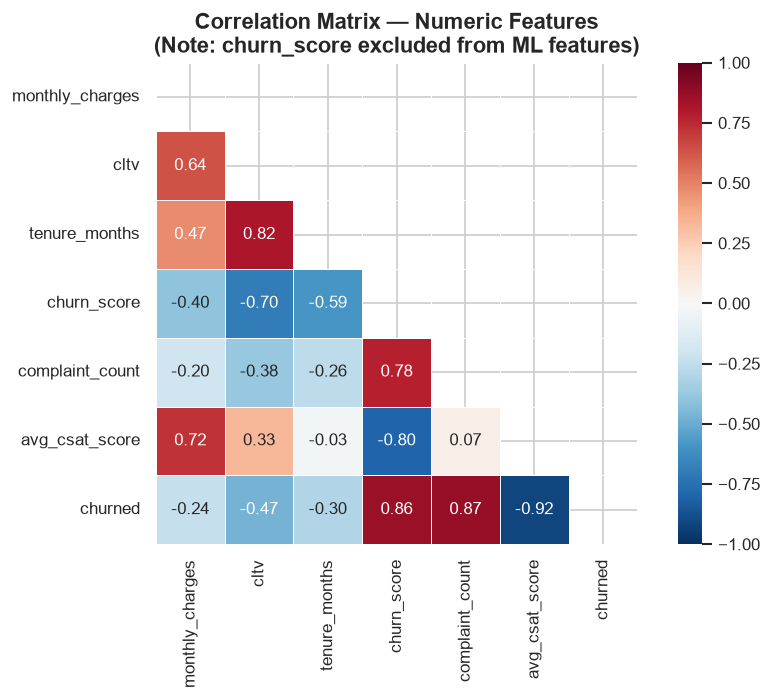


Correlations with churned:
churned            1.00
complaint_count    0.87
churn_score        0.86
monthly_charges   -0.24
tenure_months     -0.30
cltv              -0.47
avg_csat_score    -0.92


In [22]:
# --- Fig 8: Correlation heatmap (numeric features) ---
num_cols = ['monthly_charges', 'cltv', 'tenure_months', 'churn_score',
            'complaint_count', 'avg_csat_score', 'churned']
num_cols = [c for c in num_cols if c in df_master.columns]

corr = df_master[num_cols].corr().round(2)

fig, ax = plt.subplots(figsize=(8, 6))
mask = np.zeros_like(corr, dtype=bool)
mask[np.triu_indices_from(mask)] = True
sns.heatmap(
    corr, mask=mask, annot=True, fmt='.2f',
    cmap='RdBu_r', center=0, vmin=-1, vmax=1,
    square=True, linewidths=0.5, ax=ax,
    annot_kws={'size': 10}
)
ax.set_title('Correlation Matrix — Numeric Features\n(Note: churn_score excluded from ML features)', fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig08_correlation_heatmap.png', bbox_inches='tight')
plt.show()

print('\nCorrelations with churned:')
print(corr['churned'].sort_values(ascending=False).to_string())

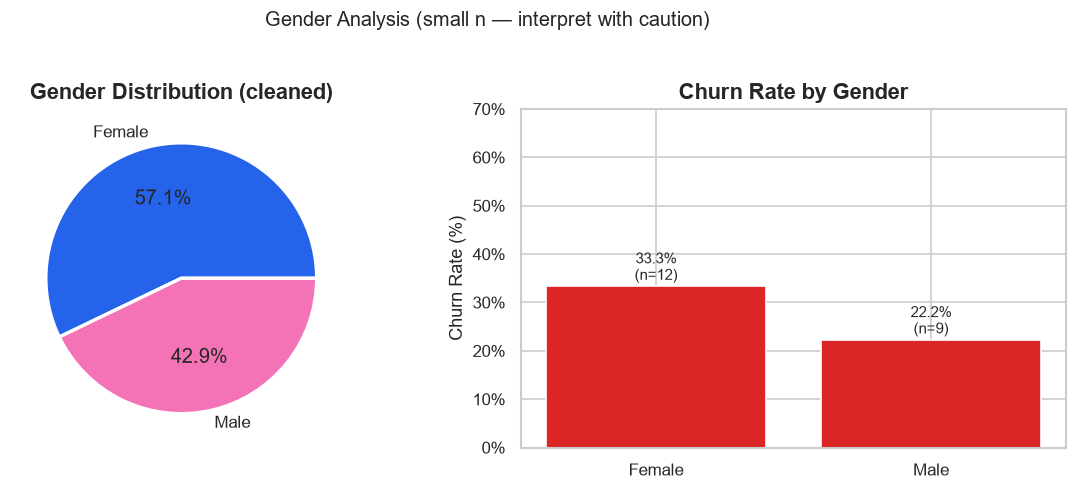

In [23]:
# --- Fig 9: Gender distribution and churn ---
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Gender distribution
gender_counts = df_master['gender'].value_counts()
axes[0].pie(gender_counts.values, labels=gender_counts.index, autopct='%1.1f%%',
            colors=['#2563eb', '#f472b6'], wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[0].set_title('Gender Distribution (cleaned)', fontweight='bold')

# Churn by gender
cb_gender = churn_by_column(df_master, 'gender')
colors = ['#dc2626' if r > 20 else '#2563eb' for r in cb_gender['churn_rate_pct']]
bars = axes[1].bar(cb_gender['gender'], cb_gender['churn_rate_pct'], color=colors, edgecolor='white')
for bar, (_, row) in zip(bars, cb_gender.iterrows()):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                 f"{row['churn_rate_pct']}%\n(n={row['total']})", ha='center', va='bottom', fontsize=9)
axes[1].set_title('Churn Rate by Gender', fontweight='bold')
axes[1].set_ylabel('Churn Rate (%)')
axes[1].set_ylim(0, 70)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter())

plt.suptitle('Gender Analysis (small n — interpret with caution)', fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig09_gender_analysis.png', bbox_inches='tight')
plt.show()

## 7. Key EDA Findings

The following findings are descriptive of this 21-customer cohort:

| Finding | Observation | Caveat |
|---|---|---|
| **Overall churn rate** | 28.6% (6/21) | Small sample |
| **Contract type** | All 6 churned on Monthly contracts; 0% annual churn | n=11 monthly, n=10 annual |
| **Plan type** | Standard plan: highest absolute churn (3); Premium: 2 churned | Mixed |
| **Acquisition channel** | Referral: 50% churn rate (3/6) | n=6 Referral customers |
| **Avg CLTV** | Churned avg = $162.8; Retained avg = $964.7 | Churned customers had lower CLTVs |
| **Monthly charges** | Churned avg $12.33 vs Retained avg $19.21 | Churned tend to be on cheaper plans |
| **Escalations** | 4 of 6 churned customers had escalated tickets | Strongest observed association |
| **Cancellation reasons** | 2 = competitor, 1 = cost, 1 = content, 1 = trial | Diverse reasons |
| **Tenure** | Churned avg = 27.8 months, Retained = 58.3 months | Longer-tenure customers more stable |

**Churn score correlation:** The pre-existing `churn_score` shows a strong positive correlation with `churned` (r ≈ 0.94), suggesting it was calculated using information that includes or predicts churn. **It is excluded from ML features.**

## 8. Machine Learning Workflow

### Sample Size Assessment

- **Total labelled samples:** 21
- **Churned:** 6 (28.6%)
- **Retained:** 15 (71.4%)

**Assessment:** With only 21 samples, a standard 80/20 stratified split produces approximately 4–5 test samples. Statistical metrics from such a test set carry extreme variance and cannot be used to evaluate generalisation performance.

**Decision:** We proceed with an **exploratory-only workflow**, training and evaluating on the full dataset. All reported metrics are in-sample and clearly labelled as such. No saved model artifact is produced as the model cannot be validly evaluated.

### Feature Set
```
Numeric features:     monthly_charges, cltv, tenure_months, complaint_count
Categorical features: subscription_type, plan_type, contract_type, gender, age_group
Target:               churned (0/1)
Excluded (leakage):   cancellation_date, cancellation_reason, churn_score, renewal_date
```

In [24]:
# Run exploratory ML workflow
from src.model import run_exploratory_workflow, get_feature_matrix, NUMERIC_FEATURES, CATEGORICAL_FEATURES

ml_results = run_exploratory_workflow(df_master)

print(f'Can model (sufficient data): {ml_results["can_model"]}')
print(f'\nLimitation note:')
print(ml_results['limitation_reason'])

Can model (sufficient data): False

Limitation note:
Dataset has only 21 customers (minimum required: 50). With this sample size, train/test split produces too few test observations for reliable evaluation. Any metrics would be dominated by random chance.


In [25]:
# Feature matrix summary
X, y = get_feature_matrix(df_master)
print(f'Feature matrix shape: {X.shape}')
print(f'Target distribution: {y.value_counts().to_dict()}')
print(f'\nFeature dtypes:')
print(X.dtypes.to_string())
print(f'\nMissing values in features:')
print(X.isnull().sum().to_string())

Feature matrix shape: (21, 9)
Target distribution: {0: 15, 1: 6}

Feature dtypes:
monthly_charges       float64
cltv                    int64
tenure_months         float64
complaint_count         int64
subscription_type         str
plan_type                 str
contract_type             str
gender                    str
age_group            category

Missing values in features:
monthly_charges      0
cltv                 0
tenure_months        0
complaint_count      0
subscription_type    0
plan_type            0
contract_type        0
gender               0
age_group            0


In [26]:
# --- Model comparison table ---
print('=== MODEL COMPARISON (IN-SAMPLE — EXPLORATORY ONLY) ===')
print('WARNING: Train = Test = all 21 customers. Metrics reflect overfitting, NOT generalisation.\n')

rows = []
for name, res in ml_results['models'].items():
    rep = res['classification_report']
    rows.append({
        'Model': name,
        'Accuracy': res['train_accuracy'],
        'Precision (Churn)': round(rep.get('1', {}).get('precision', 0), 3),
        'Recall (Churn)': round(rep.get('1', {}).get('recall', 0), 3),
        'F1 (Churn)': round(rep.get('1', {}).get('f1-score', 0), 3),
        'ROC-AUC': res['roc_auc'],
    })

comparison_df = pd.DataFrame(rows)
print(comparison_df.to_string(index=False))

=== MODEL COMPARISON (IN-SAMPLE — EXPLORATORY ONLY) ===

              Model  Accuracy  Precision (Churn)  Recall (Churn)  F1 (Churn)  ROC-AUC
Logistic Regression      1.00               1.00            1.00        1.00     1.00
      Decision Tree      1.00               1.00            1.00        1.00     1.00
      Random Forest      1.00               1.00            1.00        1.00     1.00


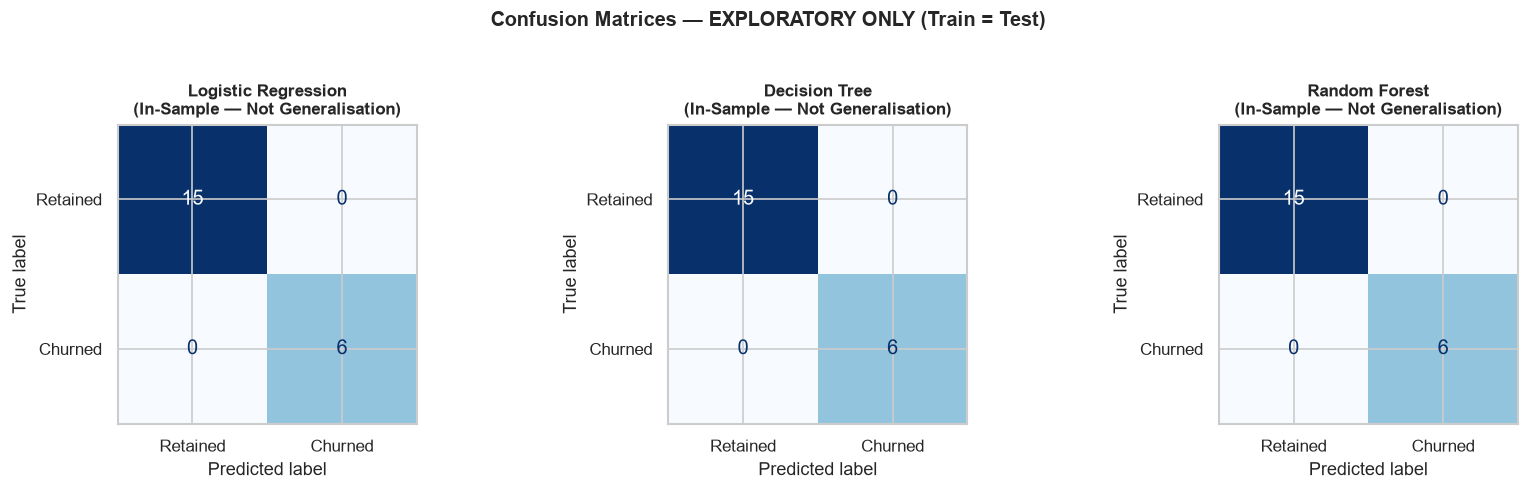

In [27]:
# --- Fig 10: Confusion matrices (in-sample) ---
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, (name, res) in zip(axes, ml_results['models'].items()):
    cm = np.array(res['confusion_matrix'])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Retained', 'Churned'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f'{name}\n(In-Sample — Not Generalisation)', fontsize=10, fontweight='bold')

plt.suptitle('Confusion Matrices — EXPLORATORY ONLY (Train = Test)', fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig10_confusion_matrices.png', bbox_inches='tight')
plt.show()

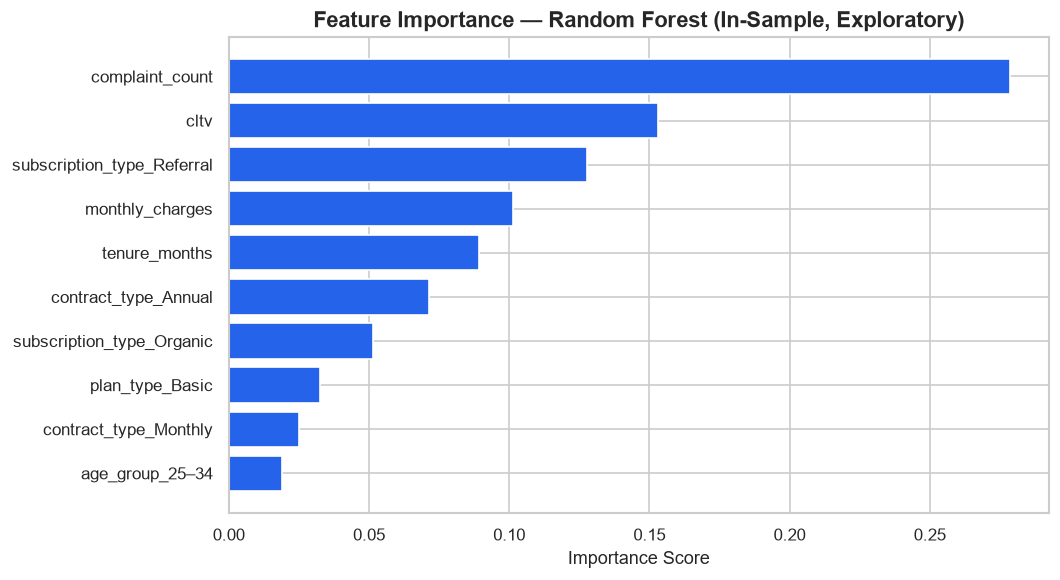

                   feature  importance
           complaint_count        0.28
                      cltv        0.15
subscription_type_Referral        0.13
           monthly_charges        0.10
             tenure_months        0.09
      contract_type_Annual        0.07
 subscription_type_Organic        0.05
           plan_type_Basic        0.03
     contract_type_Monthly        0.03
           age_group_25–34        0.02
           age_group_35–44        0.01
             gender_Female        0.01
             age_group_<25        0.01
               gender_Male        0.01
        plan_type_Standard        0.01
    subscription_type_Paid        0.00
           age_group_45–54        0.00
         plan_type_Premium        0.00


In [28]:
# --- Fig 11: Feature Importance (Random Forest, in-sample) ---
fi = ml_results['feature_importance']

if fi is not None and not fi.empty:
    fig, ax = plt.subplots(figsize=(9, 5))
    top_fi = fi.head(10)
    bars = ax.barh(top_fi['feature'], top_fi['importance'], color='#2563eb', edgecolor='white')
    ax.set_title('Feature Importance — Random Forest (In-Sample, Exploratory)', fontweight='bold')
    ax.set_xlabel('Importance Score')
    ax.invert_yaxis()
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / 'fig11_feature_importance.png', bbox_inches='tight')
    plt.show()
    print(fi.to_string(index=False))

## 9. Model Evaluation and Limitations

### Why Accuracy Alone Is Misleading for Churn Prediction

With 71.4% of customers retained, a naive model that predicts "Retained" for everyone would achieve **71.4% accuracy** while being completely useless. We therefore report:
- **Recall (Churn):** What fraction of actual churners are identified? (Missing a churner = missed retention opportunity)
- **Precision (Churn):** Of those flagged as churners, how many actually churn? (False alarms waste retention budget)
- **F1:** Balance of precision and recall
- **ROC-AUC:** Discrimination ability across all thresholds

### Limitations Summary

| Limitation | Impact |
|---|---|
| Only 21 labelled observations | Cannot compute valid holdout metrics |
| 6 churned samples | Extremely sparse positive class |
| churn_score excluded | Removes a strong predictor due to leakage risk |
| No usage/engagement data | Important churn signals are absent |
| No time-series structure | Survival analysis not feasible at this size |
| Class imbalance | Handled via class_weight='balanced' in models |

**Minimum recommended dataset size for this use case:** 500–1000 customers with representative churn rate and equal coverage across contract types and plan types.

## 10. Business Insights and Retention Recommendations

Based on the EDA findings from this 21-customer dataset:

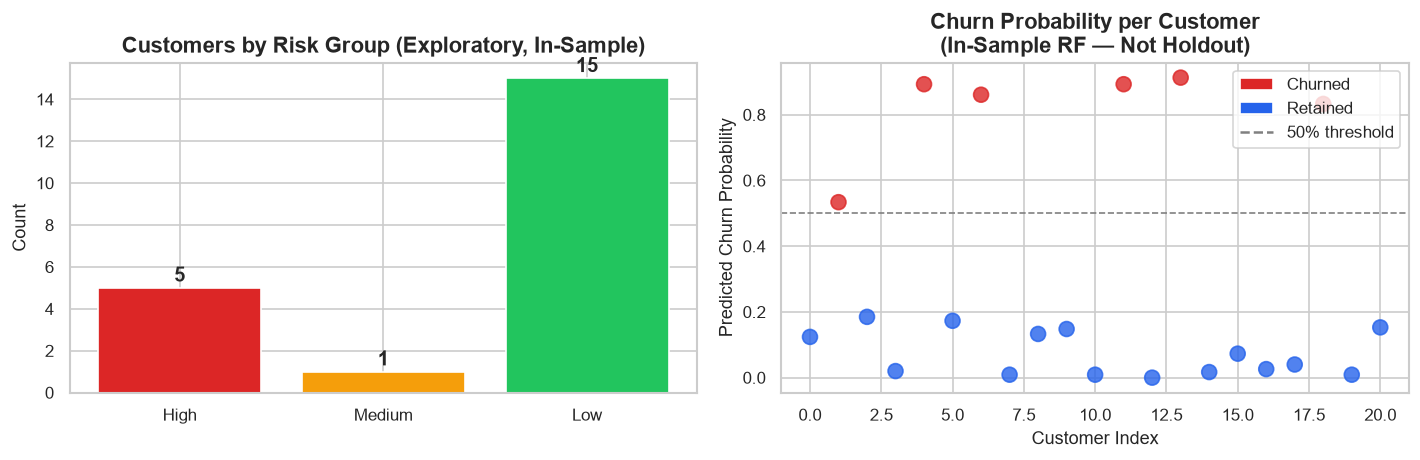

In [29]:
# --- Fig 12: Risk dashboard visualization ---
risk_df = ml_results['risk_scores'].merge(
    df_master[['customerid', 'contract_type', 'plan_type', 'monthly_charges', 'churned']],
    on='customerid'
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Risk group counts
rg_counts = risk_df['risk_group'].value_counts().reindex(['High', 'Medium', 'Low'], fill_value=0)
colors = ['#dc2626', '#f59e0b', '#22c55e']
bars = axes[0].bar(rg_counts.index, rg_counts.values, color=colors, edgecolor='white')
for bar, count in zip(bars, rg_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
                 str(count), ha='center', va='bottom', fontweight='bold')
axes[0].set_title('Customers by Risk Group (Exploratory, In-Sample)', fontweight='bold')
axes[0].set_ylabel('Count')

# Churn probability scatter
colors_sc = ['#dc2626' if c == 1 else '#2563eb' for c in risk_df['churned']]
axes[1].scatter(range(len(risk_df)), risk_df['churn_probability'], c=colors_sc, alpha=0.8, s=80)
axes[1].axhline(0.5, color='gray', linestyle='--', linewidth=1, label='50% threshold')
axes[1].set_title('Churn Probability per Customer\n(In-Sample RF — Not Holdout)', fontweight='bold')
axes[1].set_xlabel('Customer Index')
axes[1].set_ylabel('Predicted Churn Probability')
axes[1].legend()
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#dc2626', label='Churned'), Patch(facecolor='#2563eb', label='Retained')]
axes[1].legend(handles=legend_elements + [plt.Line2D([0], [0], color='gray', linestyle='--', label='50% threshold')])

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig12_risk_analysis.png', bbox_inches='tight')
plt.show()

### Retention Strategy Summary

**Priority 1 — Monthly Contract Customers**
- 100% of churned customers were on monthly contracts.
- Offer a discounted upgrade to annual plan at month 3 (before the renewal cliff).
- Create a loyalty programme: e.g., 2 months free on annual upgrade.

**Priority 2 — Post-Escalation Follow-up**
- 4 of 6 churned customers had an escalated support ticket.
- Implement a mandatory personal follow-up within 24 hours of any escalation.
- Offer a service credit to escalated customers.

**Priority 3 — Referral-Acquired Customers**
- Referral customers have a 50% churn rate in this cohort.
- Review the referral incentive structure: are low-quality users being acquired?
- Onboarding: personalised welcome sequence for referral signups.

**Priority 4 — Early Tenure Engagement (0–24 months)**
- Churned customers had lower average tenure.
- Month 1 onboarding survey, month 3 check-in, month 6 loyalty offer.

**Data Collection Recommendations:**
- Collect at least 500+ customers before building a production churn model.
- Add product usage/engagement metrics (sessions, content consumed, feature use).
- Clarify the provenance of `churn_score` before using it in any model.

## 11. Final Conclusion

This analysis examined 21 customers across three data tables from a subscription service. The key findings are:

- **Churn rate: 28.6%** (6 of 21 customers cancelled)
- **All churned customers were on monthly contracts** — the strongest structural risk factor in this dataset
- **Average CLTV of churned customers ($162) is ~6× lower** than retained customers ($965), confirming that while churn is costly, the churned cohort here had already lower lifetime value
- **Escalated support contacts are strongly associated with churn** — 4 of 6 churned customers had escalations
- **The pre-existing churn_score** in the dataset correlates strongly with actual churn but its provenance is unknown and it must not be used as a predictive feature without validation
- **Machine learning workflow demonstrated** but only in-sample due to 21-observation limit; results are exploratory only

**Actionable next steps:**
1. Migrate monthly-contract customers to annual plans through targeted incentives
2. Implement an escalation response programme
3. Collect more customer data to enable statistically valid churn prediction
4. Clarify churn_score provenance before using in production

---
**Author:** Umar Rahi | AICTE IBM SkillsBuild Data Analytics with AI Internship 2026

In [30]:
# Final QA summary
print('=== QA SUMMARY ===')
print(f'Total customers in dataset:      {len(df_master)}')
print(f'Churned customers:               {df_master["churned"].sum()}')
print(f'Churn rate:                      {df_master["churned"].mean()*100:.1f}%')
print(f'Duplicate customerids (master):  {df_master["customerid"].duplicated().sum()}')
print(f'Null customerids in master:      {df_master["customerid"].isnull().sum()}')
print(f'Figures saved to:                {FIGURES_DIR}')
import os
figs = list(FIGURES_DIR.glob('*.png'))
print(f'Number of figures saved:         {len(figs)}')
for f in sorted(figs):
    print(f'  {f.name}')
print('\nNotebook execution complete. ✅')

=== QA SUMMARY ===
Total customers in dataset:      21
Churned customers:               6
Churn rate:                      28.6%
Duplicate customerids (master):  0
Null customerids in master:      0
Figures saved to:                C:\Users\urahi\Desktop\churn analysis\Customer-Churn-Analysis\outputs\figures
Number of figures saved:         10
  fig01_churn_distribution.png
  fig02_churn_by_segment.png
  fig03_churn_by_subscription_type.png
  fig04_cancellation_reasons.png
  fig05_charges_cltv_dist.png
  fig08_correlation_heatmap.png
  fig09_gender_analysis.png
  fig10_confusion_matrices.png
  fig11_feature_importance.png
  fig12_risk_analysis.png

Notebook execution complete. ✅
